# 03 · Preprocessing and Data Split
## Kenyan Sign Language (KSL) Recognition with Deep Learning

| | |
|---|---|
| **Course** | DSA 4050-XA: Deep Learning, USIU-Africa (Fall 2026) |
| **Student** | Selmah Tzindori (669602) |
| **Notebook** | `03_preprocessing.ipynb` |
| **Term paper part** | (b) dataset preparation · (c) basis for model training |

### Objective
Turn the raw photos into a clean, model-ready dataset, applying the decisions from the EDA (notebook 02):
1. **Remove invalid images** that show no sign (no hands visible).
2. **Centre-crop every image to a square**, which removes the orientation shortcut, and **resize to 224×224**, the standard input size for pretrained CNNs.
3. **Split** into training (70%), validation (15%) and test (15%) sets, **stratified** (equal class shares) and **group-aware** (near-duplicate groups never cross splits).

### Inputs
- `data/raw/kslc_dataset.zip` (restored to local disk)
- `data/processed/catalogue_eda.csv` (from notebook 02)

### Outputs
| File | Location | Purpose |
|---|---|---|
| `ksl_224.zip` | `data/processed/` | All kept images, cropped and resized to 224×224 |
| `catalogue_split.csv` | `data/processed/` | One row per kept image: label, label index, split, processed path |
| `class_names.json` | `data/processed/` | Sign names in label-index order |
| `excluded_images.csv` | `data/processed/` | Images removed and why |
| `03_*.png`, `03_*.csv` | `outputs/` | Figures and tables for the report |

## 0 · Setup

In [1]:
# =============================================================================
# STANDARD SETUP CELL
# =============================================================================
from google.colab import drive
drive.mount("/content/drive")

import sys
sys.path.insert(0, "/content/drive/MyDrive/DSA4050/ksl-recognition/src")

import importlib
import ksl_utils as ku
importlib.reload(ku)
ku.set_seed()

NOTEBOOK = "03_preprocessing"
PATHS = ku.PATHS
print("Project root:", ku.PROJECT_ROOT)

Mounted at /content/drive
Random seed set to 42
Project root: /content/drive/MyDrive/DSA4050/ksl-recognition


### 0.1 · Update the helper module
This notebook adds three helpers to `ksl_utils.py`, used by every later notebook:
- `restore_processed_data()`: unzips the 224×224 images onto local disk
- `load_split_catalogue()`: reads the final catalogue with the train/val/test split
- `load_class_names()`: sign names in label order

The cell below rewrites the file on Drive with the updated version, then reloads it.

In [2]:
%%writefile /content/drive/MyDrive/DSA4050/ksl-recognition/src/ksl_utils.py
"""
ksl_utils.py
============
Shared helper functions for the KSL Recognition term paper (DSA 4050-XA).

Every notebook imports this file so that figures, tables, models and results
are saved in the SAME place with the SAME naming style. That makes writing
the final report easy: everything the report needs is already in outputs/.

Author : Selmah Tzindori (669602)
Course : DSA 4050-XA Deep Learning, USIU-Africa, Fall 2026
"""

import os
import json
import random
import datetime as dt

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------------------------------------------------------
# 1. PROJECT PATHS
# -----------------------------------------------------------------------------
# On Colab the project lives on Google Drive. If we are NOT on Colab
# (e.g. testing on a laptop) we fall back to a local folder so the code
# still runs. You can also override the location with the KSL_ROOT env var.
DRIVE_ROOT = "/content/drive/MyDrive/DSA4050/ksl-recognition"
LOCAL_ROOT = os.path.join(os.path.expanduser("~"), "DSA4050", "ksl-recognition")
PROJECT_ROOT = os.environ.get(
    "KSL_ROOT", DRIVE_ROOT if os.path.isdir("/content/drive") else LOCAL_ROOT
)

# Every folder the project uses, in one dictionary.
PATHS = {
    "root":       PROJECT_ROOT,
    "raw":        os.path.join(PROJECT_ROOT, "data", "raw"),        # original downloads, never edited
    "processed":  os.path.join(PROJECT_ROOT, "data", "processed"),  # cleaned / resized images, splits
    "models":     os.path.join(PROJECT_ROOT, "models"),             # trained models (.keras, .pkl)
    "checkpoints":os.path.join(PROJECT_ROOT, "models", "checkpoints"),  # best weights saved during training
    "figures":    os.path.join(PROJECT_ROOT, "outputs", "figures"), # .png charts for report and slides
    "tables":     os.path.join(PROJECT_ROOT, "outputs", "tables"),  # .csv tables for report
    "logs":       os.path.join(PROJECT_ROOT, "outputs", "logs"),    # training histories, run logs
    "src":        os.path.join(PROJECT_ROOT, "src"),                # this helper file lives here
}

# Raw dataset backup on Drive (one zip) and its fast local copy on Colab's disk.
# Reading thousands of small images straight from Drive is very slow, so each
# session we unzip the Drive backup onto Colab's local disk and work from there.
RAW_ZIP = os.path.join(PATHS["raw"], "kslc_dataset.zip")
LOCAL_DATA = "/content/ksl_data" if os.path.isdir("/content") else os.path.join(PROJECT_ROOT, "_local_data")

# Pre-processed (cropped + resized) images: zip on Drive, unzipped locally each session
PROCESSED_ZIP = os.path.join(PATHS["processed"], "ksl_224.zip")
LOCAL_PROCESSED = "/content/ksl_224" if os.path.isdir("/content") else os.path.join(PROJECT_ROOT, "_local_224")

RESULTS_FILE = os.path.join(PROJECT_ROOT, "outputs", "results.json")         # key numbers for the report
EXPERIMENTS_FILE = os.path.join(PROJECT_ROOT, "outputs", "experiments.csv")  # one row per trained model

SEED = 42  # one seed for the whole project so results can be reproduced


def make_folders(verbose: bool = True) -> None:
    """Create every project folder (safe to run many times; existing folders are kept)."""
    for name, path in PATHS.items():
        os.makedirs(path, exist_ok=True)
        if verbose:
            print(f"  ✔ {name:<12} {path}")


def restore_raw_data(local_dir: str = LOCAL_DATA) -> str:
    """
    Make the raw dataset available on Colab's fast local disk.
    - If it is already unzipped this session, do nothing.
    - Otherwise copy the zip from Drive and unzip it (about 1-2 minutes).
    Returns the local folder that holds the dataset.
    """
    import shutil, time, zipfile
    if os.path.isdir(local_dir) and os.listdir(local_dir):
        print(f"Data already available at {local_dir}")
        return local_dir
    if not os.path.exists(RAW_ZIP):
        raise FileNotFoundError(f"{RAW_ZIP} not found. Run 01_data_collection first.")
    start = time.time()
    tmp_zip = os.path.join(os.path.dirname(local_dir), "kslc_dataset_tmp.zip")
    shutil.copy(RAW_ZIP, tmp_zip)                  # Drive -> local disk (one big file is fast)
    with zipfile.ZipFile(tmp_zip) as z:
        z.extractall(local_dir)                    # unzip on local disk
    os.remove(tmp_zip)                             # free space
    print(f"Data restored to {local_dir} in {time.time() - start:.0f}s")
    return local_dir


def restore_processed_data(local_dir: str = LOCAL_PROCESSED) -> str:
    """
    Make the pre-processed 224x224 images (made in 03_preprocessing) available locally.
    Same idea as restore_raw_data(), but for the much smaller processed zip.
    """
    import shutil, time, zipfile
    if os.path.isdir(local_dir) and os.listdir(local_dir):
        print(f"Processed data already available at {local_dir}")
        return local_dir
    if not os.path.exists(PROCESSED_ZIP):
        raise FileNotFoundError(f"{PROCESSED_ZIP} not found. Run 03_preprocessing first.")
    start = time.time()
    tmp_zip = os.path.join(os.path.dirname(local_dir), "ksl_224_tmp.zip")
    shutil.copy(PROCESSED_ZIP, tmp_zip)
    with zipfile.ZipFile(tmp_zip) as z:
        z.extractall(local_dir)
    os.remove(tmp_zip)
    print(f"Processed data restored to {local_dir} in {time.time() - start:.0f}s")
    return local_dir


def load_split_catalogue():
    """Read the final catalogue (one row per kept image, with its train/val/test split)."""
    return pd.read_csv(os.path.join(PATHS["processed"], "catalogue_split.csv"))


def load_class_names() -> list:
    """Sign names in label-index order (index 0 = first name), saved by 03_preprocessing."""
    with open(os.path.join(PATHS["processed"], "class_names.json")) as f:
        return json.load(f)


# -----------------------------------------------------------------------------
# 2. REPRODUCIBILITY
# -----------------------------------------------------------------------------
def set_seed(seed: int = SEED) -> None:
    """Fix all random seeds so every run gives the same splits and (near) same results."""
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    try:
        import tensorflow as tf  # only if TensorFlow is installed
        tf.random.set_seed(seed)
    except ImportError:
        pass
    print(f"Random seed set to {seed}")


def _timestamp() -> str:
    """Current date-time as text, used to stamp every saved result."""
    return dt.datetime.now().strftime("%Y-%m-%d %H:%M:%S")


# -----------------------------------------------------------------------------
# 3. SAVING OUTPUTS FOR THE REPORT
# -----------------------------------------------------------------------------
def save_figure(fig, name: str, notebook: str, caption: str = "", dpi: int = 300) -> str:
    """
    Save a matplotlib figure as a high-resolution PNG in outputs/figures/.

    name     : short file name, e.g. "02_class_distribution"
    notebook : which notebook made it, e.g. "02_eda" (recorded in the log)
    caption  : one sentence describing the figure (re-used in the report)
    """
    path = os.path.join(PATHS["figures"], f"{name}.png")
    fig.savefig(path, dpi=dpi, bbox_inches="tight")
    _log_output("figure", name, path, notebook, caption)
    print(f"Figure saved -> {path}")
    return path


def save_table(df: pd.DataFrame, name: str, notebook: str, caption: str = "", index: bool = False) -> str:
    """Save a pandas DataFrame as CSV in outputs/tables/ (opens in Excel/Word for the report)."""
    path = os.path.join(PATHS["tables"], f"{name}.csv")
    df.to_csv(path, index=index)
    _log_output("table", name, path, notebook, caption)
    print(f"Table saved  -> {path}")
    return path


def log_result(key: str, value, notebook: str) -> None:
    """
    Store one key number/fact for the report in outputs/results.json.
    Example: log_result("n_images_total", 6249, "01_data")
    Running it again with the same key overwrites the old value.
    """
    results = load_results()
    results[key] = {"value": value, "notebook": notebook, "saved_at": _timestamp()}
    with open(RESULTS_FILE, "w") as f:
        json.dump(results, f, indent=2, default=str)
    print(f"Result logged: {key} = {value}")


def load_results() -> dict:
    """Read every logged result (empty dict if nothing logged yet)."""
    if os.path.exists(RESULTS_FILE):
        with open(RESULTS_FILE) as f:
            return json.load(f)
    return {}


def log_experiment(model_name: str, model_type: str, metrics: dict, notebook: str,
                   params: dict | None = None, notes: str = "") -> pd.DataFrame:
    """
    Add one row to outputs/experiments.csv for every trained model.
    This table becomes the model-comparison table in the report.

    model_type : "classic_ml" or "deep_learning"
    metrics    : e.g. {"accuracy": 0.91, "macro_f1": 0.90, "train_time_s": 120}
    params     : hyper-parameters used, e.g. {"epochs": 20, "lr": 1e-3}
    If the same model_name already exists, its row is replaced.
    """
    row = {"model": model_name, "type": model_type, **metrics,
           "params": json.dumps(params or {}), "notes": notes,
           "notebook": notebook, "saved_at": _timestamp()}
    if os.path.exists(EXPERIMENTS_FILE):
        df = pd.read_csv(EXPERIMENTS_FILE)
        df = df[df["model"] != model_name]             # drop old run of the same model
        df = pd.concat([df, pd.DataFrame([row])], ignore_index=True)
    else:
        df = pd.DataFrame([row])
    df.to_csv(EXPERIMENTS_FILE, index=False)
    print(f"Experiment logged: {model_name} -> {metrics}")
    return df


def _log_output(kind: str, name: str, path: str, notebook: str, caption: str) -> None:
    """Keep a list of every saved figure/table (outputs/logs/outputs_index.csv) with captions."""
    index_file = os.path.join(PATHS["logs"], "outputs_index.csv")
    row = pd.DataFrame([{"kind": kind, "name": name, "path": path, "notebook": notebook,
                         "caption": caption, "saved_at": _timestamp()}])
    if os.path.exists(index_file):
        old = pd.read_csv(index_file)
        old = old[~((old["kind"] == kind) & (old["name"] == name))]
        row = pd.concat([old, row], ignore_index=True)
    row.to_csv(index_file, index=False)


# -----------------------------------------------------------------------------
# 4. SAVING MODELS AND TRAINING HISTORY
# -----------------------------------------------------------------------------
def model_path(name: str, ext: str = "keras") -> str:
    """Full Drive path for a model file, e.g. model_path("cnn_scratch") -> .../models/cnn_scratch.keras"""
    return os.path.join(PATHS["models"], f"{name}.{ext}")


def save_history(history, name: str, notebook: str) -> str:
    """Save a Keras training history (loss/accuracy per epoch) to outputs/logs/ as CSV."""
    hist = history.history if hasattr(history, "history") else history
    df = pd.DataFrame(hist)
    df.index.name = "epoch"
    path = os.path.join(PATHS["logs"], f"history_{name}.csv")
    df.to_csv(path)
    print(f"History saved -> {path}")
    return path


def plot_history(history, name: str, notebook: str):
    """Plot and save training vs validation accuracy and loss curves side by side."""
    hist = history.history if hasattr(history, "history") else history
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, metric in zip(axes, ["accuracy", "loss"]):
        if metric in hist:
            ax.plot(hist[metric], label="train")
        if f"val_{metric}" in hist:
            ax.plot(hist[f"val_{metric}"], label="validation")
        ax.set_title(f"{name}: {metric}")
        ax.set_xlabel("epoch")
        ax.set_ylabel(metric)
        ax.legend()
    fig.tight_layout()
    save_figure(fig, f"history_{name}", notebook, caption=f"Training curves for {name}.")
    return fig


# -----------------------------------------------------------------------------
# 5. QUICK SUMMARY
# -----------------------------------------------------------------------------
def project_summary() -> None:
    """Print what has been saved so far: number of figures, tables, models and results."""
    def count(folder, ext):
        return len([f for f in os.listdir(folder) if f.endswith(ext)]) if os.path.isdir(folder) else 0
    print("Project root :", PROJECT_ROOT)
    print("Figures      :", count(PATHS["figures"], ".png"))
    print("Tables       :", count(PATHS["tables"], ".csv"))
    print("Models       :", count(PATHS["models"], ".keras") + count(PATHS["models"], ".pkl"))
    print("Results      :", len(load_results()))
    n_exp = len(pd.read_csv(EXPERIMENTS_FILE)) if os.path.exists(EXPERIMENTS_FILE) else 0
    print("Experiments  :", n_exp)


Overwriting /content/drive/MyDrive/DSA4050/ksl-recognition/src/ksl_utils.py


In [3]:
# Reload so the new helpers are available in this session
importlib.reload(ku)
print("Helpers available:", all(hasattr(ku, f) for f in
      ["restore_processed_data", "load_split_catalogue", "load_class_names"]))

Helpers available: True


In [4]:
# Libraries used in this notebook
import os
import json
import shutil
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image
from tqdm.auto import tqdm

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 11})
SPLIT_COLOURS = {"train": "#2E7D6B", "val": "#E0A458", "test": "#B5482B"}

In [6]:
# Restore raw images and load the catalogue from notebook 02
DATA_DIR = Path(ku.restore_raw_data())
df = pd.read_csv(os.path.join(PATHS["processed"], "catalogue_eda.csv"))
df["abs_path"] = df["rel_path"].apply(lambda p: str(DATA_DIR / p))
SIGNS = sorted(df["label"].unique())
print(f"{len(df)} images, {len(SIGNS)} signs")

Data restored to /content/ksl_data in 31s
6249 images, 9 signs


## 1 · Find images with no visible sign
Notebook 02 found photos that show **no hands at all** (fabric close-ups, empty walls). These cannot teach the model anything and would add label noise.

Checking 6,249 images by eye is not practical, so we **screen automatically** and then **review only the suspicious ones**:
- **Skin-pixel ratio:** every sign is made with bare hands and forearms, so each valid image contains skin. Each image is converted to the **YCrCb colour space**, where skin tones of all shades fall in a compact range (Cr 133–173, Cb 77–127), and we measure the share of skin-coloured pixels in the centre square.
- Images with the **lowest skin ratio** are shown in a numbered grid for review.

Skin detection by colour is approximate (warm-coloured clothing or walls can look like skin, and dim lighting can hide it), which is why the final decision is made by eye.

In [7]:
def centre_square(img: Image.Image) -> Image.Image:
    """Crop the largest centred square from an image (the crop used throughout the project)."""
    w, h = img.size
    side = min(w, h)
    left, top = (w - side) // 2, (h - side) // 2
    return img.crop((left, top, left + side, top + side))


def skin_ratio(path: str) -> float:
    """Share of skin-coloured pixels in the centre square (YCrCb rule), measured at 128x128."""
    with Image.open(path) as img:
        img.draft("RGB", (256, 256))                    # fast reduced-size decode
        sq = centre_square(img.convert("RGB")).resize((128, 128))
    ycrcb = cv2.cvtColor(np.asarray(sq), cv2.COLOR_RGB2YCrCb)
    cr, cb = ycrcb[..., 1], ycrcb[..., 2]
    mask = (cr >= 133) & (cr <= 173) & (cb >= 77) & (cb <= 127)
    return float(mask.mean())


df["skin_ratio"] = [skin_ratio(p) for p in tqdm(df["abs_path"], desc="Measuring skin ratio")]
print(df["skin_ratio"].describe().round(3).to_string())

Measuring skin ratio:   0%|          | 0/6249 [00:00<?, ?it/s]

count    6249.000
mean        0.460
std         0.195
min         0.000
25%         0.318
50%         0.445
75%         0.589
max         1.000


Figure saved -> /content/drive/MyDrive/DSA4050/ksl-recognition/outputs/figures/03_skin_ratio_hist.png


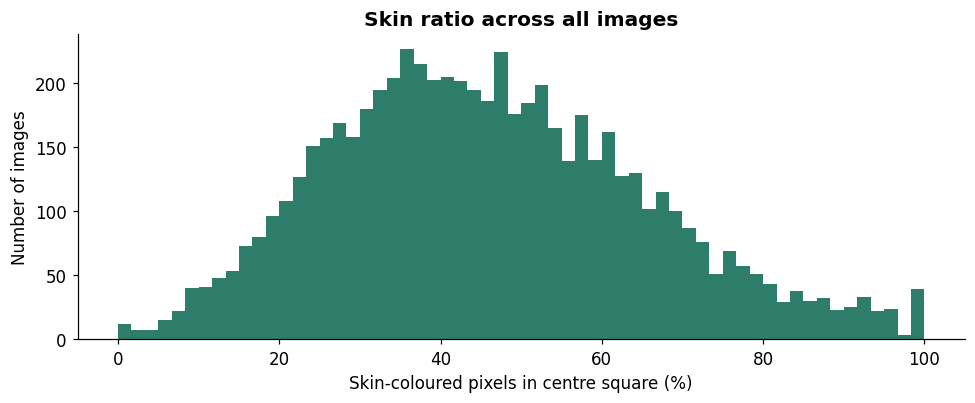

Images with skin ratio < 1%: 11
Images with skin ratio < 2%: 13
Images with skin ratio < 5%: 26


In [8]:
# Distribution of skin ratio, with the share of images below a few cut-offs
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(df["skin_ratio"] * 100, bins=60, color="#2E7D6B")
ax.set_xlabel("Skin-coloured pixels in centre square (%)")
ax.set_ylabel("Number of images")
ax.set_title("Skin ratio across all images")
fig.tight_layout()
ku.save_figure(fig, "03_skin_ratio_hist", NOTEBOOK, caption="Distribution of the share of skin-coloured pixels per image.")
plt.show()

for cut in [0.01, 0.02, 0.05]:
    print(f"Images with skin ratio < {cut:.0%}: {(df['skin_ratio'] < cut).sum()}")

### 1.1 · Review the 48 most suspicious images
The 48 images with the lowest skin ratio are shown with a **number** above each one. Look at each image and note the numbers of those that **show no sign** (no hands or arms performing a sign).

Figure saved -> /content/drive/MyDrive/DSA4050/ksl-recognition/outputs/figures/03_review_low_skin.png


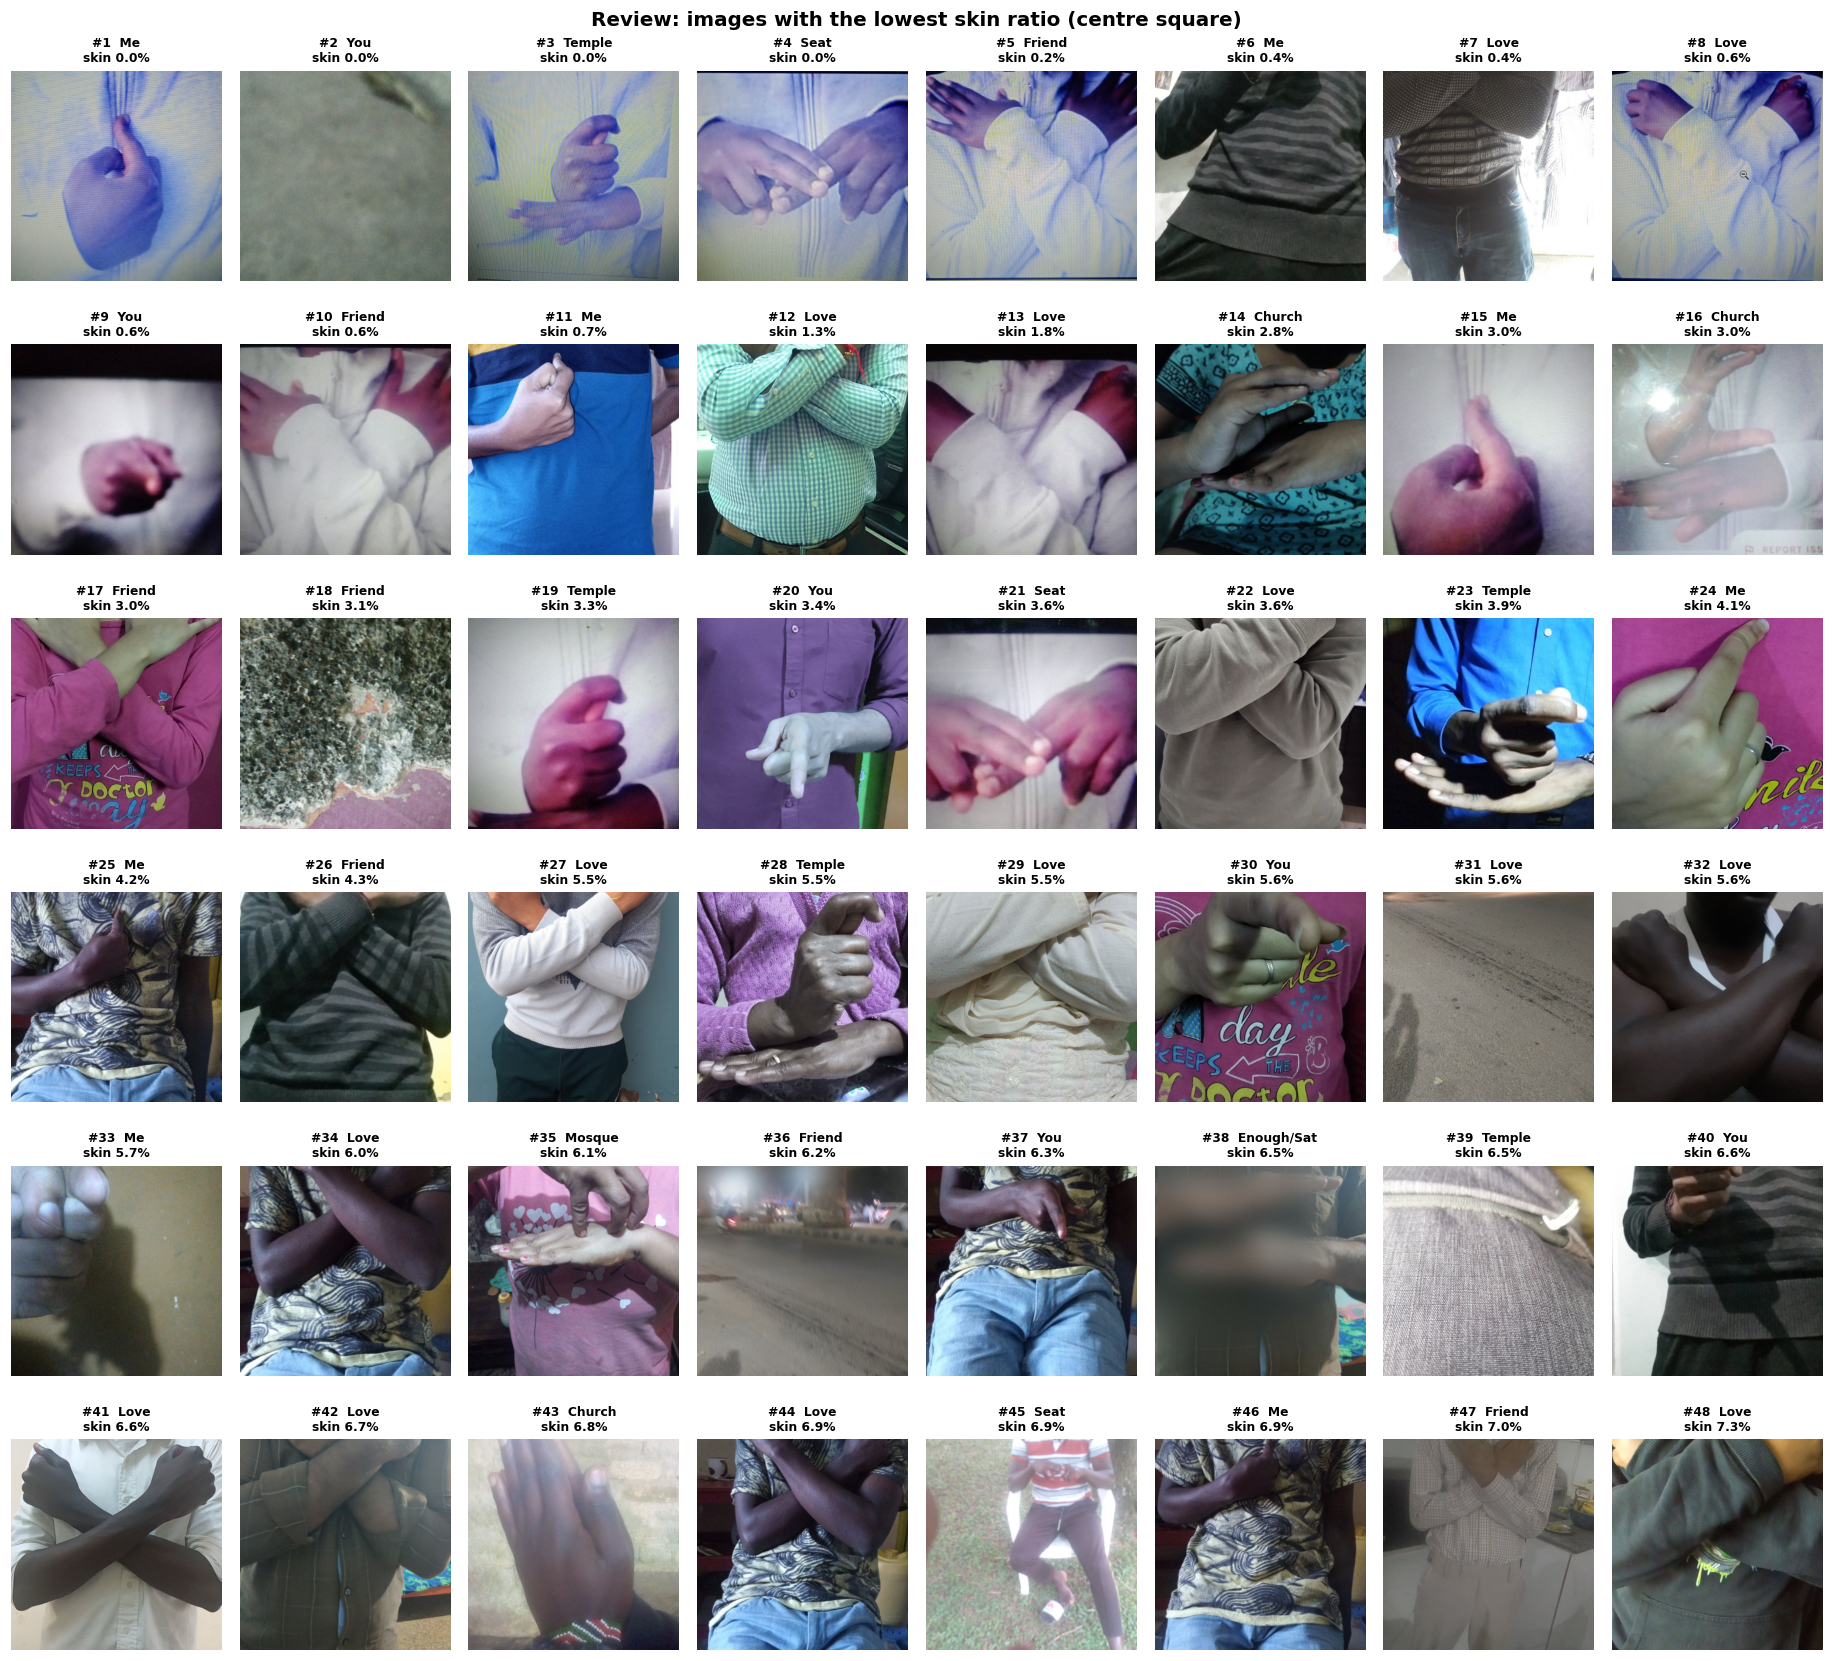

In [9]:
N_REVIEW = 48
review = df.nsmallest(N_REVIEW, "skin_ratio").reset_index()   # 'index' = row in df
review["review_no"] = range(1, len(review) + 1)

n_cols = 8
n_rows = int(np.ceil(len(review) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.1 * n_cols, 2.6 * n_rows))
for ax, (_, row) in zip(axes.flat, review.iterrows()):
    with Image.open(row["abs_path"]) as img:
        img.draft("RGB", (256, 256))
        ax.imshow(centre_square(img.convert("RGB")))
    ax.set_title(f"#{row['review_no']}  {row['label'][:10]}\nskin {row['skin_ratio']:.1%}", fontsize=8)
    ax.axis("off")
for ax in list(axes.flat)[len(review):]:
    ax.axis("off")
fig.suptitle("Review: images with the lowest skin ratio (centre square)", fontsize=13, fontweight="bold")
fig.tight_layout()
ku.save_figure(fig, "03_review_low_skin", NOTEBOOK, caption="The 48 images with the lowest skin ratio, reviewed by eye.")
plt.show()

### 1.2 · Record the decision
The review numbers of images whose **centre square shows no sign** go into `NO_SIGN_REVIEW_NOS` below. The centre square is what the model will see, so an image is removed if the hands are absent from it, even if they might be visible elsewhere in the original photo.

From the review of the grid above (first run), 8 images show no sign:

| # | Label | What the image shows |
|---|---|---|
| 2 | You | Blank grey surface |
| 6 | Me | Torso in a striped sweater, no hand in frame |
| 7 | Love | Torso and jeans, arms not in frame |
| 18 | Friend | Close-up of a stone or granite surface |
| 31 | Love | Bare ground or floor |
| 36 | Friend | Street scene at night |
| 38 | Enough/Satisfied | Entirely blurred, no shape recognisable |
| 39 | Temple | Close-up of fabric (the near-duplicate group from notebook 02) |

If an excluded image belongs to a **near-duplicate group with mixed labels** (like the fabric close-ups), the whole group is removed, because its other members are copies of the same invalid photo.

**Note on the skin screen:** many images with clearly visible hands scored low because the signers have **darker skin** (e.g. #32, #41, #44), which falls outside the fixed YCrCb range. Rule-based skin detection is known to be biased against darker skin tones, which is why a human makes the final decision here and why a learned model is preferable to hand-written colour rules.

In [10]:
# Review numbers of images whose centre square shows no sign (see table above)
NO_SIGN_REVIEW_NOS = [2, 6, 7, 18, 31, 36, 38, 39]

# 1. Images chosen by eye from the review grid
by_review = review.loc[review["review_no"].isin(NO_SIGN_REVIEW_NOS), "index"].tolist()

# 2. Their near-duplicate partners, if the group mixes labels (copies of the same invalid photo)
group_info = df.groupby("dup_group").agg(n=("label", "size"), n_labels=("label", "nunique"))
mixed_groups = group_info[(group_info["n"] > 1) & (group_info["n_labels"] > 1)].index
bad_groups = set(df.loc[by_review, "dup_group"]) & set(mixed_groups)
by_group = [i for i in df.index[df["dup_group"].isin(bad_groups)] if i not in by_review]

excluded_idx = sorted(set(by_review) | set(by_group))
excluded = df.loc[excluded_idx, ["image_id", "label", "rel_path", "skin_ratio", "dup_group"]].copy()
excluded["reason"] = np.where(excluded.index.isin(by_review), "no sign visible (manual review)",
                              "near-duplicate of an excluded image (mixed-label group)")
excluded.to_csv(os.path.join(PATHS["processed"], "excluded_images.csv"), index=False)

ku.save_table(excluded[["image_id", "label", "skin_ratio", "reason"]].round(3), "03_excluded_images", NOTEBOOK,
              caption="Images removed because they show no sign.")
ku.log_result("n_excluded_no_sign", len(excluded), NOTEBOOK)
print(f"Excluded: {len(excluded)} images")
excluded

Table saved  -> /content/drive/MyDrive/DSA4050/ksl-recognition/outputs/tables/03_excluded_images.csv
Result logged: n_excluded_no_sign = 11
Excluded: 11 images


,image_id,label,rel_path,skin_ratio,dup_group,reason
605,ImageID_6IWDCR84,Love,Images/Images/ImageID_6IWDCR84.jpg,0.056335,605,no sign visible (manual review)
1099,ImageID_L3XB0109,Friend,Images/Images/ImageID_L3XB0109.jpg,0.061584,1098,no sign visible (manual review)
1840,ImageID_SOXPPFY7,Enough/Satisfied,Images/Images/ImageID_SOXPPFY7.jpg,0.091614,1839,near-duplicate of an excluded image (mixed-lab...
2994,ImageID_24CNR8Q5,Me,Images/Images/ImageID_24CNR8Q5.jpg,0.003540,2992,no sign visible (manual review)
3197,ImageID_Y03JC7Z2,Enough/Satisfied,Images/Images/ImageID_Y03JC7Z2.jpg,0.065186,3195,no sign visible (manual review)
3480,ImageID_EX8EVQ7A,Temple,Images/Images/ImageID_EX8EVQ7A.jpg,0.065186,1839,no sign visible (manual review)
4317,ImageID_WMETEGZQ,You,Images/Images/ImageID_WMETEGZQ.jpg,0.000000,4311,no sign visible (manual review)
5069,ImageID_WY7ECZNS,Love,Images/Images/ImageID_WY7ECZNS.jpg,0.097412,1839,near-duplicate of an excluded image (mixed-lab...
5174,ImageID_CFLDK4S2,Me,Images/Images/ImageID_CFLDK4S2.jpg,0.124146,1839,near-duplicate of an excluded image (mixed-lab...
5611,ImageID_QALYD6AQ,Friend,Images/Images/ImageID_QALYD6AQ.jpg,0.031311,5598,no sign visible (manual review)


In [11]:
# Keep only valid images
clean = df.drop(index=excluded_idx).reset_index(drop=True)
ku.log_result("n_images_after_cleaning", len(clean), NOTEBOOK)
print(f"Images kept: {len(clean)} of {len(df)}")
print(clean["label"].value_counts().reindex(SIGNS).to_string())

Result logged: n_images_after_cleaning = 6238
Images kept: 6238 of 6249
label
Church              694
Enough/Satisfied    693
Friend              692
Love                691
Me                  692
Mosque              695
Seat                695
Temple              693
You                 693


## 2 · Centre-crop and resize to 224 × 224
Every image is cropped to its **largest centred square** (720×720 for both orientations) and resized to **224×224 pixels**:
- the square crop removes the orientation cue found in notebook 02 (all images end up the same shape);
- 224×224 is the input size of the pretrained CNNs used later (MobileNetV2, EfficientNet, ResNet), and smaller models can downscale it further;
- resizing once here, instead of during every training epoch, makes training much faster.

**Before and after** for a few examples:

Figure saved -> /content/drive/MyDrive/DSA4050/ksl-recognition/outputs/figures/03_crop_before_after.png


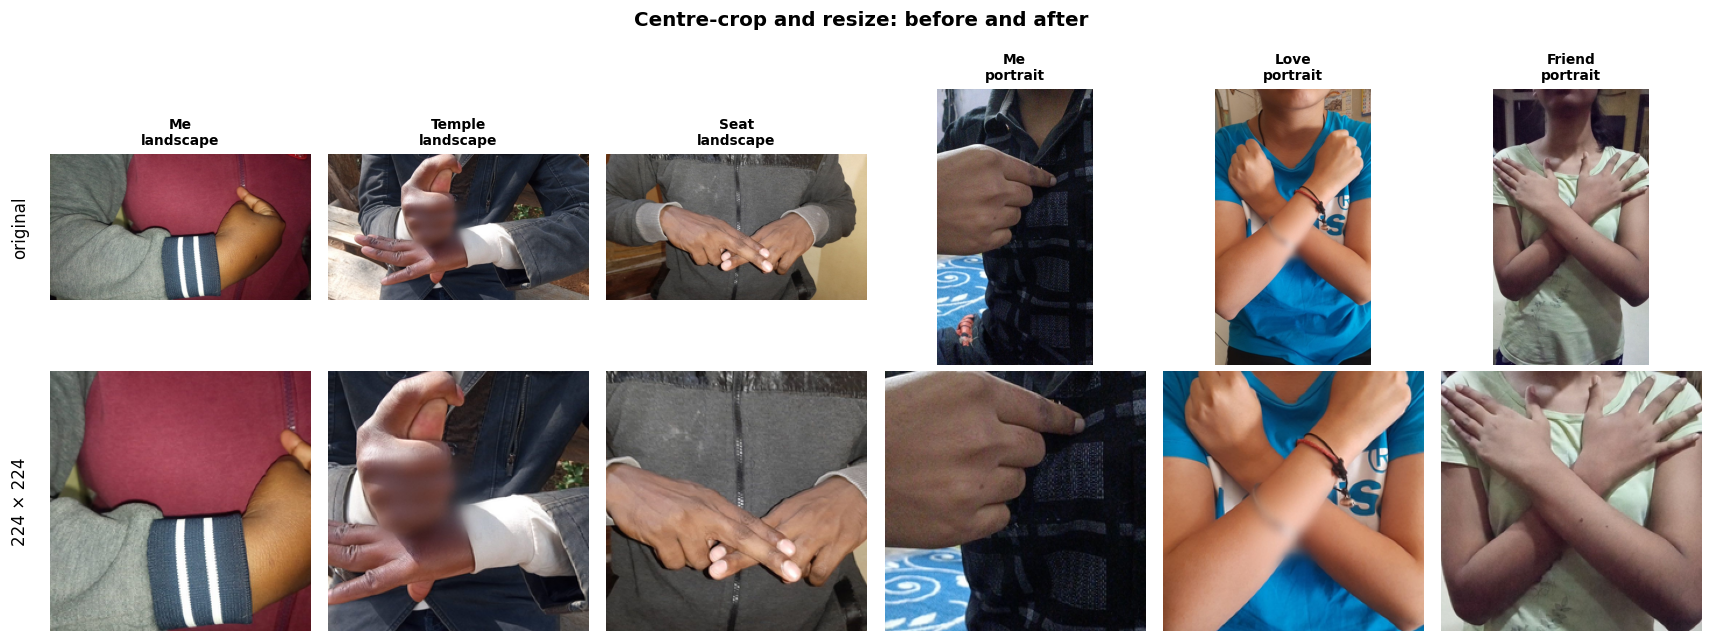

In [12]:
IMG_SIZE = 224

examples = clean.groupby("orientation").sample(3, random_state=ku.SEED)
fig, axes = plt.subplots(2, len(examples), figsize=(2.6 * len(examples), 6))
for c, (_, row) in enumerate(examples.iterrows()):
    with Image.open(row["abs_path"]) as img:
        img.draft("RGB", (400, 400))
        img = img.convert("RGB")
        axes[0, c].imshow(img)
        axes[1, c].imshow(centre_square(img).resize((IMG_SIZE, IMG_SIZE), Image.Resampling.LANCZOS))
    axes[0, c].set_title(f"{row['label']}\n{row['orientation']}", fontsize=9)
    for r in range(2):
        axes[r, c].axis("off")
axes[0, 0].text(-0.15, 0.5, "original", transform=axes[0, 0].transAxes, rotation=90, va="center", fontsize=11)
axes[1, 0].text(-0.15, 0.5, "224 × 224", transform=axes[1, 0].transAxes, rotation=90, va="center", fontsize=11)
fig.suptitle("Centre-crop and resize: before and after", fontsize=13, fontweight="bold")
fig.tight_layout()
ku.save_figure(fig, "03_crop_before_after", NOTEBOOK, caption="Original images and their 224×224 centre-cropped versions.")
plt.show()

**Interpretation:** for **portrait** photos the square crop removes the head and legs and keeps the full sign, and the hands become larger in the frame, which helps the model. For **landscape** photos the crop removes the sides; in most cases the sign stays inside, but occasionally part of a hand near the edge is cut (e.g. the *Me* landscape example, where the hand sits at the right edge). Since only 21% of images are landscape and the hands are usually central, this is an acceptable trade-off for removing the orientation shortcut, and it is noted as a limitation.

In [13]:
# Process every kept image and write it as a high-quality JPEG on local disk
OUT_DIR = Path(ku.LOCAL_PROCESSED)
if OUT_DIR.exists():
    shutil.rmtree(OUT_DIR)                       # start clean if re-running
OUT_DIR.mkdir(parents=True)

for _, row in tqdm(clean.iterrows(), total=len(clean), desc="Cropping + resizing"):
    with Image.open(row["abs_path"]) as img:
        img.draft("RGB", (IMG_SIZE * 2, IMG_SIZE * 2))   # decode at reduced size (faster, same quality at 224)
        out = centre_square(img.convert("RGB")).resize((IMG_SIZE, IMG_SIZE), Image.Resampling.LANCZOS)
    out.save(OUT_DIR / f"{row['image_id']}.jpg", quality=95)

clean["proc_file"] = clean["image_id"] + ".jpg"
print(f"Wrote {len(list(OUT_DIR.glob('*.jpg')))} images to {OUT_DIR}")

Cropping + resizing:   0%|          | 0/6238 [00:00<?, ?it/s]

Wrote 6238 images to /content/ksl_224


## 3 · Train / validation / test split
| Set | Share | Used for |
|---|---|---|
| **Train** | 70% | Fitting model weights |
| **Validation** | 15% | Choosing settings (epochs, learning rate) and early stopping |
| **Test** | 15% | Final, untouched evaluation reported in the paper |

The split is:
- **group-aware**: the unit being split is the near-duplicate **group** (from notebook 02), so all images of a group land in the **same** set, preventing leakage. Most groups are single images.
- **stratified**: groups are split with each sign keeping the same share in every set (each group is assigned the most common label among its images).

The fixed seed makes the split reproducible.

In [14]:
from sklearn.model_selection import train_test_split

# One row per near-duplicate group, labelled with its most common sign
groups = (clean.groupby("dup_group")["label"]
               .agg(lambda s: s.value_counts().index[0])
               .rename("group_label").reset_index())

# Step 1: 15% of groups -> test; Step 2: 15% of all (= 15/85 of the rest) -> validation
trainval_g, test_g = train_test_split(groups, test_size=0.15, stratify=groups["group_label"],
                                      random_state=ku.SEED)
train_g, val_g = train_test_split(trainval_g, test_size=0.15 / 0.85, stratify=trainval_g["group_label"],
                                  random_state=ku.SEED)

split_of_group = {**{g: "train" for g in train_g["dup_group"]},
                  **{g: "val" for g in val_g["dup_group"]},
                  **{g: "test" for g in test_g["dup_group"]}}
clean["split"] = clean["dup_group"].map(split_of_group)

# Label index: signs in alphabetical order -> 0..8 (saved so every notebook uses the same mapping)
class_names = SIGNS
clean["label_idx"] = clean["label"].map({s: i for i, s in enumerate(class_names)})
with open(os.path.join(PATHS["processed"], "class_names.json"), "w") as f:
    json.dump(class_names, f, indent=2)

split_sizes = clean["split"].value_counts().reindex(["train", "val", "test"])
print((split_sizes.to_frame("images").assign(percent=(100 * split_sizes / len(clean)).round(1))).to_string())

       images  percent
split                 
train    4362     69.9
val       935     15.0
test      941     15.1


In [15]:
# Check 1: no near-duplicate group appears in more than one split
groups_across = clean.groupby("dup_group")["split"].nunique()
n_leaky = int((groups_across > 1).sum())
print(f"Near-duplicate groups split across sets: {n_leaky}  (must be 0)")
assert n_leaky == 0

# Check 2: class balance in each split
split_table = pd.crosstab(clean["label"], clean["split"])[["train", "val", "test"]].reindex(SIGNS)
split_table.loc["Total"] = split_table.sum()
ku.save_table(split_table.reset_index(names="sign"), "03_split_counts", NOTEBOOK,
              caption="Number of images per sign in the training, validation and test sets.")

for s in ["train", "val", "test"]:
    ku.log_result(f"n_{s}", int(split_sizes[s]), NOTEBOOK)
split_table

Near-duplicate groups split across sets: 0  (must be 0)
Table saved  -> /content/drive/MyDrive/DSA4050/ksl-recognition/outputs/tables/03_split_counts.csv
Result logged: n_train = 4362
Result logged: n_val = 935
Result logged: n_test = 941


split,train,val,test
label,,,
Church,486,104,104
Enough/Satisfied,484,104,105
Friend,484,103,105
Love,484,104,103
Me,483,104,105
Mosque,487,104,104
Seat,486,104,105
Temple,484,104,105
You,484,104,105


Figure saved -> /content/drive/MyDrive/DSA4050/ksl-recognition/outputs/figures/03_split_by_sign.png


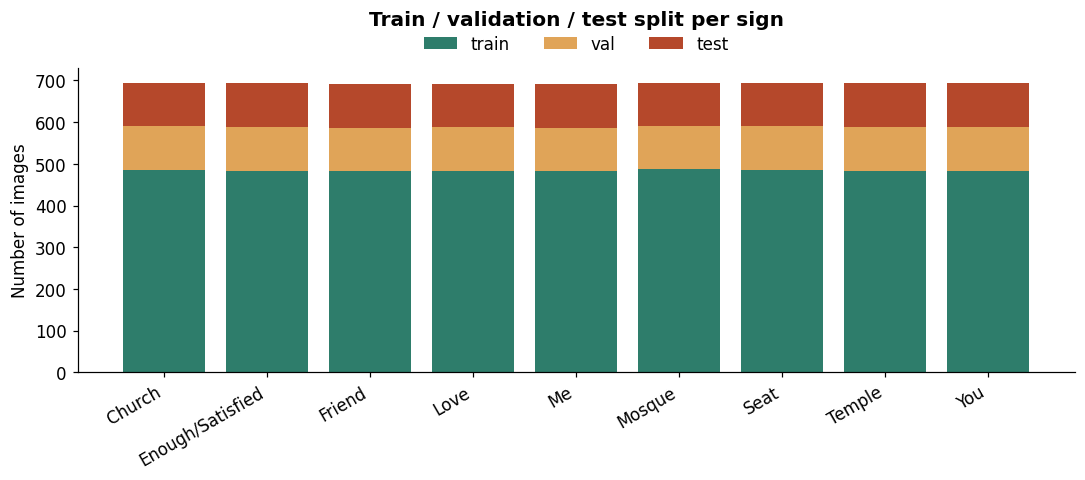

In [16]:
# Chart: images per sign in each split
plot_df = split_table.drop(index="Total")
fig, ax = plt.subplots(figsize=(10, 4.5))
bottom = np.zeros(len(plot_df))
for s in ["train", "val", "test"]:
    ax.bar(plot_df.index, plot_df[s], bottom=bottom, label=s, color=SPLIT_COLOURS[s])
    bottom += plot_df[s].values
ax.set_ylabel("Number of images")
ax.set_title("Train / validation / test split per sign", pad=28)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False)
plt.xticks(rotation=30, ha="right")
fig.tight_layout()
ku.save_figure(fig, "03_split_by_sign", NOTEBOOK, caption="Stratified, group-aware split of each sign into train, validation and test sets.")
plt.show()

**Interpretation:** the split is **almost exactly 70 / 15 / 15** for every sign: 483–487 training, 103–104 validation and 103–105 test images per sign (4,362 / 935 / 941 in total). Check 1 confirms that **no near-duplicate group crosses sets**, so there is no leakage from duplicate photos. The test set stays untouched until the final evaluation.

## 4 · Save the processed dataset
- The 224×224 images are zipped into **`ksl_224.zip`** on Drive (around 100 MB). Later notebooks restore them with `ku.restore_processed_data()` in a few seconds.
- **`catalogue_split.csv`** records, for every kept image, its label, label index, split and processed file name.

In [17]:
# Zip the processed images to Drive
tmp_zip = "/content/ksl_224.zip" if os.path.isdir("/content") else str(OUT_DIR) + ".zip"
with zipfile.ZipFile(tmp_zip, "w", compression=zipfile.ZIP_STORED) as z:
    for p in tqdm(sorted(OUT_DIR.glob("*.jpg")), desc="Zipping"):
        z.write(p, arcname=p.name)
shutil.copy(tmp_zip, ku.PROCESSED_ZIP)
os.remove(tmp_zip)
print(f"Saved {ku.PROCESSED_ZIP} ({os.path.getsize(ku.PROCESSED_ZIP) / 1e6:.0f} MB)")

# Save the final catalogue
cols = ["image_id", "label", "label_idx", "split", "proc_file", "orientation",
        "brightness", "contrast", "sharpness", "is_blurry", "skin_ratio", "dup_group"]
clean[cols].to_csv(os.path.join(PATHS["processed"], "catalogue_split.csv"), index=False)
print("Saved catalogue_split.csv:", clean[cols].shape)

Zipping:   0%|          | 0/6238 [00:00<?, ?it/s]

Saved /content/drive/MyDrive/DSA4050/ksl-recognition/data/processed/ksl_224.zip (129 MB)
Saved catalogue_split.csv: (6238, 12)


In [18]:
# Final check: reload everything the next notebooks will use
cat = ku.load_split_catalogue()
names = ku.load_class_names()
print("Catalogue rows :", len(cat))
print("Class names    :", names)
print("Split sizes    :", cat["split"].value_counts().to_dict())
missing = [f for f in cat["proc_file"] if not (OUT_DIR / f).exists()]
print("Missing processed files:", len(missing))

Catalogue rows : 6238
Class names    : ['Church', 'Enough/Satisfied', 'Friend', 'Love', 'Me', 'Mosque', 'Seat', 'Temple', 'You']
Split sizes    : {'train': 4362, 'test': 941, 'val': 935}
Missing processed files: 0


## Check · Project status

In [19]:
ku.project_summary()

Project root : /content/drive/MyDrive/DSA4050/ksl-recognition
Figures      : 12
Tables       : 10
Models       : 0
Results      : 38
Experiments  : 0


## Findings for the report
- **Cleaning:** a skin-colour screen ranked all images, and the 48 most suspicious were reviewed by eye. **8 images showed no sign** (blank surfaces, ground, a street scene, fabric, torsos with no hands in frame, one fully blurred image), plus **3 near-duplicate copies** of the fabric image, so **11 images (0.2%) were removed**, leaving **6,238**.
- **Bias in rule-based vision:** the skin-colour rule under-detected the hands of **darker-skinned signers**, scoring clearly visible hands as "no skin". This illustrates the bias of hand-crafted colour rules and supports learning features from data, with a human checking any rule-based filtering.
- **Preprocessing:** every image was **centre-cropped to a square** (removing the portrait/landscape cue) and **resized to 224×224**, the standard input for pretrained CNNs. Hands become larger in portrait images; in a few landscape images part of a hand near the edge is lost.
- **Split:** stratified and group-aware: **4,362 train (69.9%), 935 validation (15.0%), 941 test (15.1%)**, with 103–105 test images per sign and no near-duplicate group across sets.
- **Storage:** processed images saved as `ksl_224.zip` (129 MB) on Drive; the final catalogue and class order (`class_names.json`) are shared by all later notebooks.

**Next notebook:** `04_classic_ml.ipynb`: classic machine-learning baselines on hand-crafted image features.